# 16.21 - GigiKita single-class crowding baseline

This is one bounded, source-specific YOLO11s detection experiment. It trains on the duplicate-grouped GigiKita train split and selects checkpoints using only the new validation split. It does not open the source test split. The source's `crowded` labels are used as provided; metrics describe this export, not clinical or phone-camera accuracy.

**Why this baseline:** YOLO11s is the stronger visible YOLO11 checkpoint in the existing project and is still small enough for a practical mobile-export investigation later. The study keeps one dataset, one architecture, one seed and one protocol to avoid score shopping. Research anchor: the 2026 YOLOv11 dental-malocclusion study in the project research report motivates YOLO11 family detection, but its private-data scores are not comparable to this dataset.

**Expected result:** source-validation precision, recall, mAP50 and mAP50-95 plus curves and confusion matrix. Do not treat a high score as evidence of external validity.

## 1. Runtime and reproducibility

Use Kaggle T4 x2. The time guard leaves room inside the 12-hour session. The same seed and fixed train/validation manifest are recorded with artifacts.

In [ ]:
import os, sys, json, time, random, hashlib, zipfile, shutil
from pathlib import Path
import numpy as np

SEED = 51324
random.seed(SEED); np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
print({'python': sys.version.split()[0], 'seed': SEED, 'cuda_visible_devices': os.environ.get('CUDA_VISIBLE_DEVICES')})
!nvidia-smi

## 2. Recover and verify the frozen input

Only the packaged train/validation derivative is attached. Check the expected manifest hash and image/label inventories before training.

In [ ]:
INPUT_ROOT=Path('/kaggle/input')
assert INPUT_ROOT.exists(), f'Kaggle input mount not found: {INPUT_ROOT}'
top_level=sorted(p.name for p in INPUT_ROOT.iterdir())
print('Mounted input entries:', top_level)
EXPECTED_MANIFEST_SHA256='44d39f856f80508da95eafcaecd49c362f3e34b9d8b2b0f8729281c54229c488'
existing_manifests=list(INPUT_ROOT.rglob('manifest.csv'))
if existing_manifests:
    DATA_ROOT=existing_manifests[0].parent
else:
    archives=list(INPUT_ROOT.rglob('*.zip'))
    if not archives:
        raise FileNotFoundError(f'No manifest.csv or zip under /kaggle/input. Top level: {top_level}')
    DATA_ROOT=Path('/kaggle/working/crowding_dataset')
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archives[0]) as zf: zf.extractall(DATA_ROOT)
summary=json.loads((DATA_ROOT/'split_summary.json').read_text())
manifest_sha=hashlib.sha256((DATA_ROOT/'manifest.csv').read_bytes()).hexdigest()
assert manifest_sha==EXPECTED_MANIFEST_SHA256, (manifest_sha, summary)
assert summary['source_test_opened'] is False and not (DATA_ROOT/'test').exists()
print({'data_root':str(DATA_ROOT), **{k:summary[k] for k in ['train_images','valid_images','train_positive_images','valid_positive_images','train_boxes','valid_boxes','excluded_duplicate_label_conflict_groups','manifest_sha256']}})
for split,expected in [('train',5516),('valid',1357)]:
    images=list((DATA_ROOT/split/'images').glob('*')); labels=list((DATA_ROOT/split/'labels').glob('*.txt'))
    assert len(images)==len(labels)==expected
print('Integrity checks passed: image-label pairing, frozen manifest, no test directory.')

## 3. Audit labels and split isolation

This verifies that all boxes use the single class index 0 and normalized YOLO coordinates, and that visual duplicate groups do not cross splits.

In [ ]:
import csv, collections
rows=list(csv.DictReader((DATA_ROOT/'manifest.csv').open(encoding='utf-8')))
groups={s:{r['group_id'] for r in rows if r['split']==s} for s in ['train','valid']}
assert not groups['train'] & groups['valid']
bad=[]; box_counts=collections.Counter()
for split in ['train','valid']:
    for p in (DATA_ROOT/split/'labels').glob('*.txt'):
        for line_no,line in enumerate(p.read_text().splitlines(),1):
            v=line.split(); box_counts[split]+=1
            if len(v)!=5 or v[0]!='0' or any(not 0<=float(x)<=1 for x in v[1:]): bad.append((p.name,line_no,line))
assert not bad, bad[:5]
print({'train_groups':len(groups['train']), 'validation_groups':len(groups['valid']),
       'cross_split_group_overlap':0, 'box_counts':dict(box_counts), 'invalid_boxes':len(bad)})

## 4. Prepare the single YOLO11s run

The transfer-learning baseline uses the official COCO-pretrained YOLO11s checkpoint, one target class and a fixed seed. Mild geometric/color augmentation is used; vertical flips are disabled because they create implausible mouth orientation. A time cap and early stopping bound the session. The full run is one experiment, not a hyperparameter search.

In [ ]:
%pip -q install ultralytics==8.3.203
from ultralytics import YOLO
import torch, yaml
assert torch.cuda.is_available(), 'Kaggle GPU is not available'
gpu_count=torch.cuda.device_count()
print({'torch':torch.__version__, 'cuda':torch.version.cuda, 'gpu_count':gpu_count,
       'gpus':[torch.cuda.get_device_name(i) for i in range(gpu_count)]})
assert gpu_count >= 1
runtime_yaml=Path('/kaggle/working/crowding_data.yaml')
runtime_yaml.write_text(yaml.safe_dump({'path':str(DATA_ROOT), 'train':'train/images', 'val':'valid/images', 'nc':1, 'names':['crowded']}))
RUN_ROOT=Path('/kaggle/working/runs/crowding_yolo11s_seed51324')
RUN_ROOT.mkdir(parents=True, exist_ok=True)
model=YOLO('yolo11s.pt')
train_start=time.time()
train_result=model.train(data=str(runtime_yaml), imgsz=640, epochs=25, patience=6,
    batch=32, workers=4, device=0 if gpu_count==1 else [0,1], seed=SEED, deterministic=True,
    optimizer='AdamW', lr0=0.001, cos_lr=True, amp=True, time=8.0,
    fliplr=0.5, flipud=0.0, degrees=5.0, translate=0.05, scale=0.10,
    hsv_h=0.005, hsv_s=0.25, hsv_v=0.15, mosaic=0.5, close_mosaic=5,
    save=True, save_period=2, plots=True, project=str(RUN_ROOT), name='train', exist_ok=True)
train_hours=(time.time()-train_start)/3600
print({'wall_hours':round(train_hours,3), 'run_dir':str(RUN_ROOT/'train')})

## 5. Validate the selected best checkpoint

Report source-validation metrics from the best checkpoint. The validation set was fixed before training; it is used for early stopping and checkpoint selection, so these are model-selection metrics rather than an untouched final test estimate.

In [ ]:
run_dir=RUN_ROOT/'train'
best_path=run_dir/'weights'/'best.pt'
assert best_path.exists(), f'Missing best checkpoint: {best_path}'
best=YOLO(str(best_path))
metrics=best.val(data=str(runtime_yaml), split='val', imgsz=640, batch=32,
                 device=0 if gpu_count==1 else 0, plots=True, project=str(RUN_ROOT), name='best_validation')
metric_row={'precision':float(metrics.box.mp), 'recall':float(metrics.box.mr),
            'mAP50':float(metrics.box.map50), 'mAP50_95':float(metrics.box.map),
            'best_checkpoint':str(best_path), 'training_hours':round(train_hours,3)}
print(json.dumps(metric_row, indent=2))

## 6. Save compact, inspectable evidence

Keep the training log, results table, validation plots and best checkpoint together. These are source-validation results; do not tune repeatedly on this same split and call it a test result.

In [ ]:
import shutil, json
ARTIFACTS=Path('/kaggle/working/crowding_baseline_artifacts')
ARTIFACTS.mkdir(parents=True, exist_ok=True)
for name in ['results.csv','results.png','confusion_matrix.png','confusion_matrix_normalized.png','PR_curve.png','F1_curve.png','P_curve.png','R_curve.png']:
    src=run_dir/name
    if src.exists(): shutil.copy2(src, ARTIFACTS/name)
shutil.copy2(best_path, ARTIFACTS/'best.pt')
(ARTIFACTS/'summary.json').write_text(json.dumps({
    'source':'GigiKita Roboflow version 1, declared CC BY 4.0', 'task':'source-defined crowded object detection',
    'seed':SEED, 'manifest_sha256':manifest_sha, 'source_test_opened':False,
    'train_images':5516, 'validation_images':1357, 'metrics':metric_row}, indent=2))
print('Artifacts:', [(p.name, round(p.stat().st_size/1e6,2)) for p in ARTIFACTS.iterdir()])

## Collected run results

This section reads the saved outputs from the completed Kaggle v4 run. It does not retrain the model. The summary reports an independent validation pass using best.pt; results.csv records per-epoch validation and may differ slightly. The source test split remains unopened.


| Best-checkpoint validation metric | Result |
|---|---:|
| Precision | 61.56% |
| Recall | 61.48% |
| mAP50 | 62.82% |
| mAP50-95 | 27.44% |

{'artifact_root': 'data\\runs\\alignment_gigikita_crowding_v4', 'manifest_sha256': '44d39f856f80508da95eafcaecd49c362f3e34b9d8b2b0f8729281c54229c488', 'source_test_opened': False, 'training_hours': 0.888, 'results_csv_epoch_rows': 37, 'peak_csv_epoch_by_map50_95': 31, 'peak_csv_map50': 0.62913, 'peak_csv_map50_95': 0.27538}


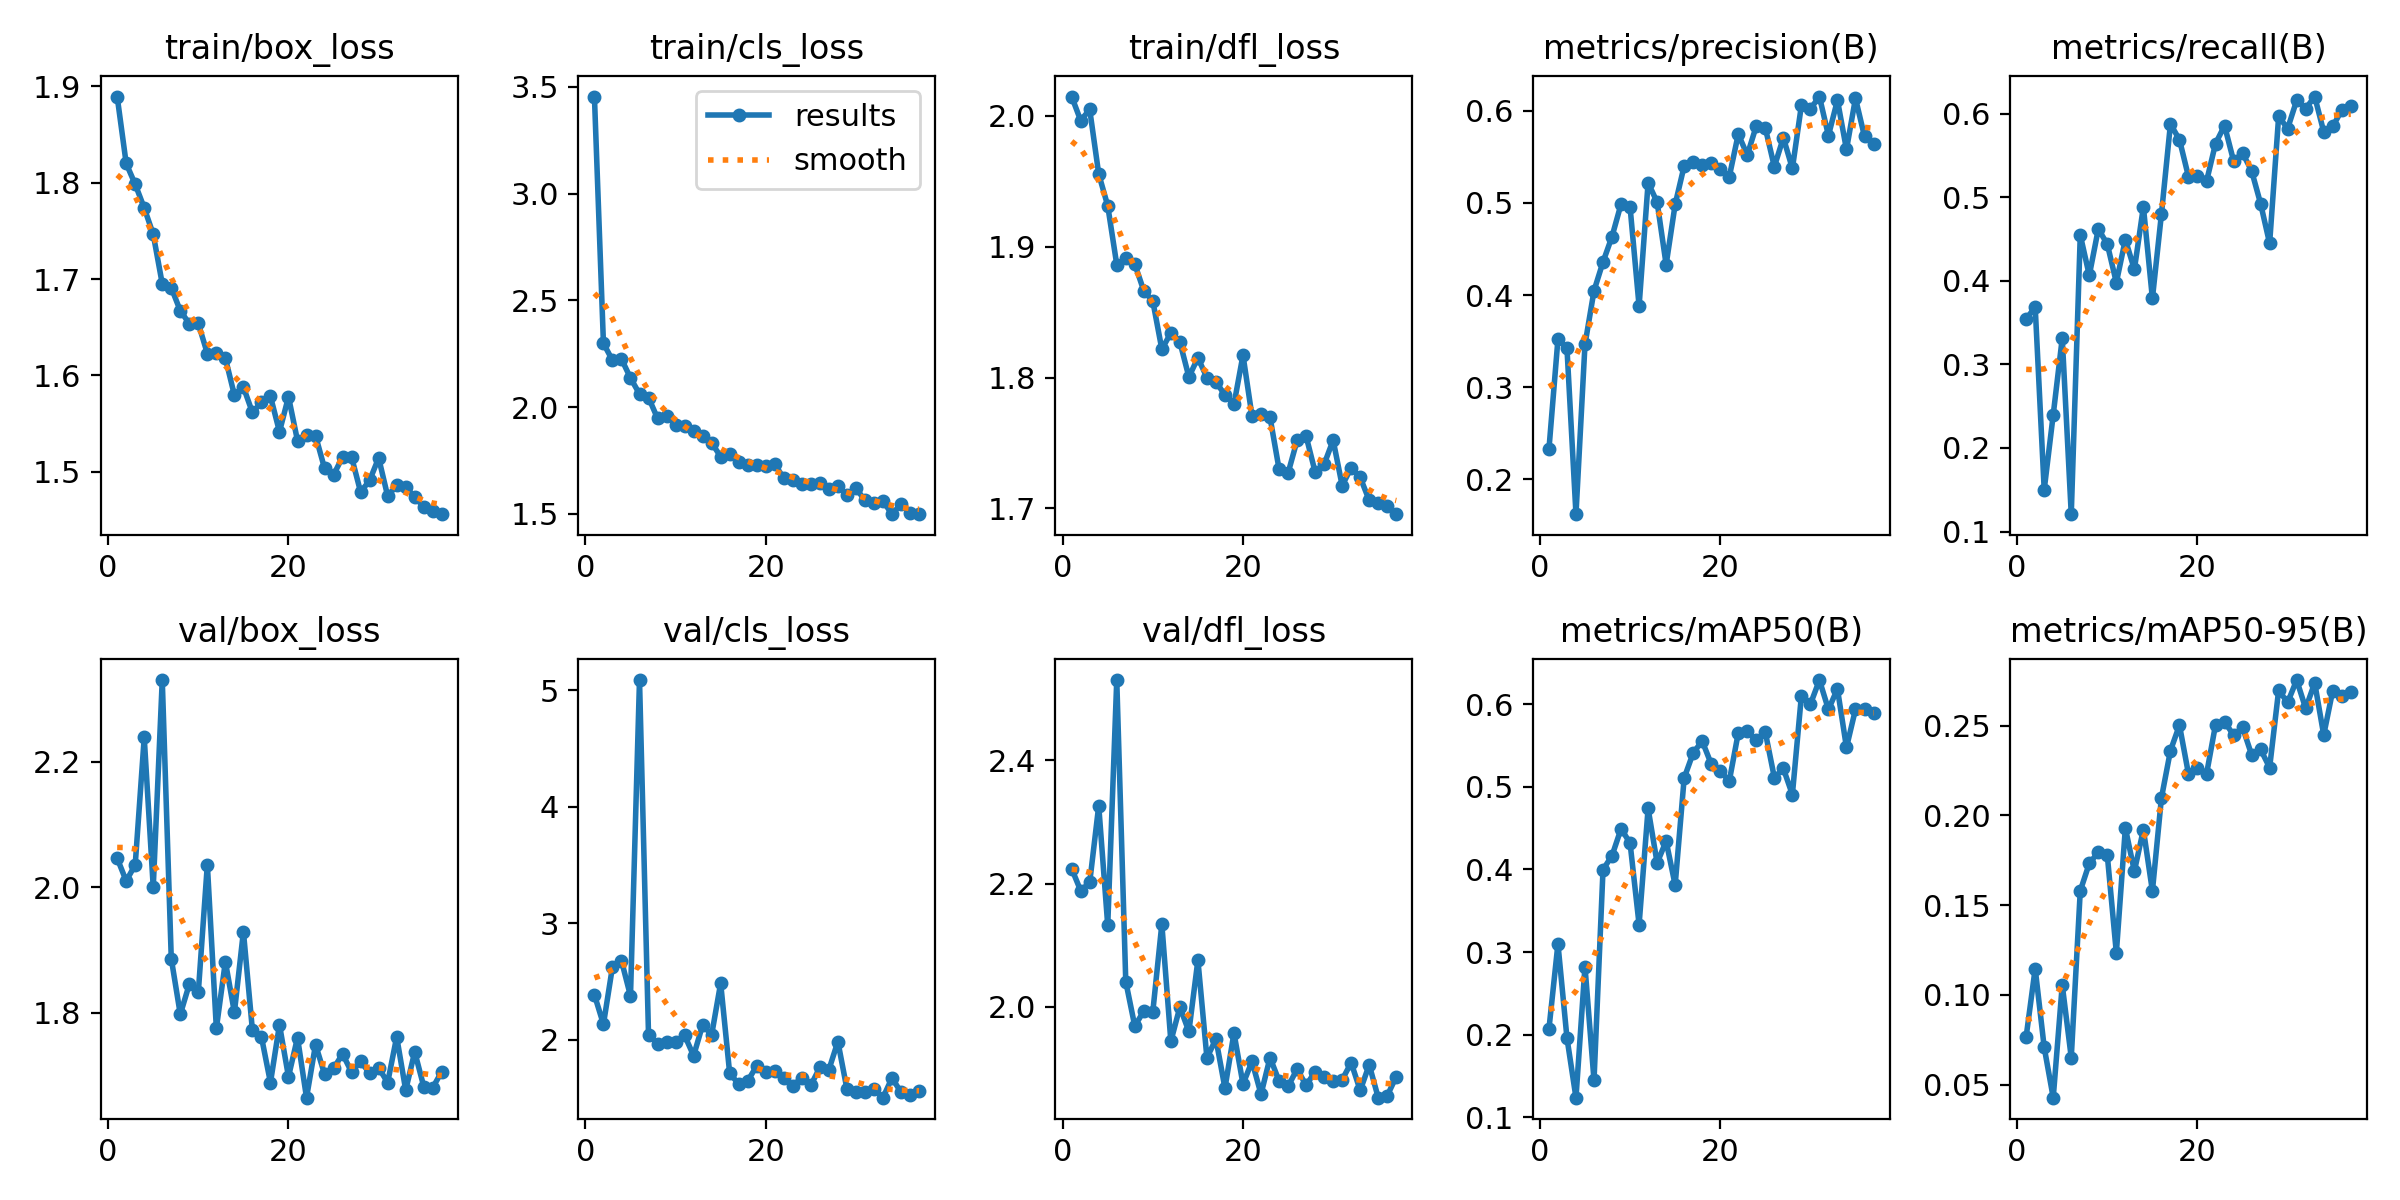

In [1]:
import csv, json
from pathlib import Path
from IPython.display import display, Markdown, Image

ARTIFACT_CANDIDATES = [
    Path('/kaggle/working/crowding_baseline_artifacts'),
    Path('data/runs/alignment_gigikita_crowding_v4'),
]
ARTIFACT_ROOT = next((p for p in ARTIFACT_CANDIDATES if (p / 'summary.json').is_file()), None)
assert ARTIFACT_ROOT is not None, f'Collected run artifacts not found. Checked: {ARTIFACT_CANDIDATES}'
summary = json.loads((ARTIFACT_ROOT / 'summary.json').read_text(encoding='utf-8'))
assert summary['manifest_sha256'] == '44d39f856f80508da95eafcaecd49c362f3e34b9d8b2b0f8729281c54229c488'
assert summary['source_test_opened'] is False
metric = summary['metrics']
with (ARTIFACT_ROOT / 'results.csv').open(encoding='utf-8-sig', newline='') as f:
    epoch_rows = list(csv.DictReader(f))
peak_row = max(epoch_rows, key=lambda r: float(r['metrics/mAP50-95(B)']))

display(Markdown(
    '| Best-checkpoint validation metric | Result |\n'
    '|---|---:|\n'
    f'| Precision | {metric["precision"]:.2%} |\n'
    f'| Recall | {metric["recall"]:.2%} |\n'
    f'| mAP50 | {metric["mAP50"]:.2%} |\n'
    f'| mAP50-95 | {metric["mAP50_95"]:.2%} |'
))
print({
    'artifact_root': str(ARTIFACT_ROOT),
    'manifest_sha256': summary['manifest_sha256'],
    'source_test_opened': summary['source_test_opened'],
    'training_hours': metric['training_hours'],
    'results_csv_epoch_rows': len(epoch_rows),
    'peak_csv_epoch_by_map50_95': int(float(peak_row['epoch'])),
    'peak_csv_map50': float(peak_row['metrics/mAP50(B)']),
    'peak_csv_map50_95': float(peak_row['metrics/mAP50-95(B)']),
})
curve_path = ARTIFACT_ROOT / 'results.png'
if curve_path.is_file():
    display(Image(filename=str(curve_path)))
